# Problem Set 5 - Support Vector Machine


Submitted by: <b>Lanuzo, Jessica Mae T. | BSCS-2A </b>
***
Download a classification dataset from the UCI Machine Learning Repository. 

Then, explore the dataset using the code implementation of Support Vector Machine explained in the link: https://stackabuse.com/implementing-svm-and-kernel-svm-with-pythons-scikit-learn/

Write a report containing two (2) sections describing the Dataset and the Result. Submit the report file named as PS5_LastName_Section.pdf and a zip file named as PS5_LastName_Section.zip containing your code and the dataset. Lastly, submit a similarity rating by following this instruction: https://medium.com/@renatoivadriano/turnitin-draft-coach-cspc-institutional-support-walkthrough-54a3e9629fa9. Allowable similarity score is below 20%.

     The Dataset: Occupancy Detection

> Experimental data used for binary classification (room occupancy) from Temperature,Humidity,Light and CO2. Ground-truth occupancy was obtained from time stamped pictures that were taken every minute. 

> Repository URL: https://archive.ics.uci.edu/dataset/357/occupancy+detection.

***
### **SVM on Occupancy Detection Dataset**


#### Load and Prepare the Dataset

In [1]:
import pandas as pd

file1 = "datatest.txt"
file2 = "datatest2.txt"
file3 = "datatraining.txt"

# Read files into dfs
df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)
df3 = pd.read_csv(file3)

# Concatenate into one df
df = pd.concat([df1, df2, df3], ignore_index=True)
df = df.drop(columns=['date']) # exclude date column

df.head()

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,23.7000,26.272,585.200000,749.200000,0.004764,1
1,23.7180,26.290,578.400000,760.400000,0.004773,1
2,23.7300,26.230,572.666667,769.666667,0.004765,1
3,23.7225,26.125,493.750000,774.750000,0.004744,1
4,23.7540,26.200,488.600000,779.000000,0.004767,1


In [2]:
# Check class column values
df['Occupancy'].unique()

array([1, 0])

#### Explore the Dataset

###### *Checking Class Distribution*

In [3]:
# Check if classes are balanced
df['Occupancy'].value_counts()

Occupancy
0    15810
1     4750
Name: count, dtype: int64

In [4]:
df['Occupancy'].value_counts(normalize=True)

Occupancy
0    0.768969
1    0.231031
Name: proportion, dtype: float64

<Axes: ylabel='Frequency'>

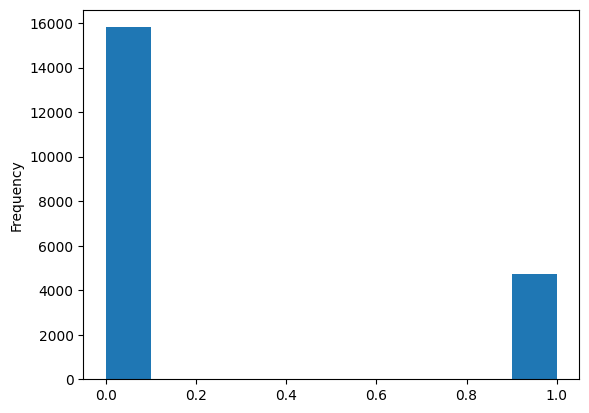

In [5]:
df['Occupancy'].plot.hist()

###### *Balancing Class Distribution*

Occupancy
1    15810
0    15810
Name: count, dtype: int64


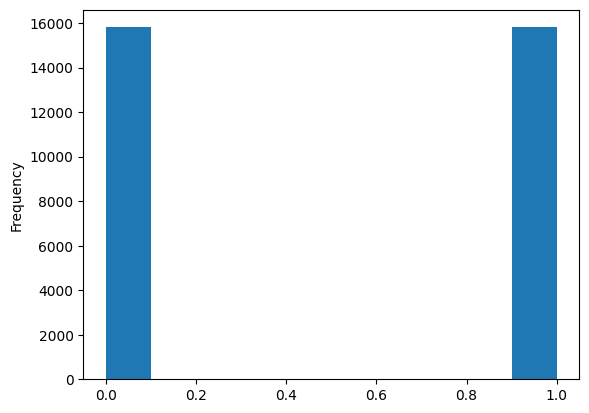

In [6]:
from imblearn.over_sampling import SMOTE

# Features and labels
X = df[["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]]
y = df['Occupancy']

# SMOTE to balance classes
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Combine back to DataFrame
df_balanced = pd.DataFrame(X_resampled, columns=["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"])
df_balanced['Occupancy'] = y_resampled

# Check new class distribution
df_balanced['Occupancy'].plot.hist()
print(df_balanced['Occupancy'].value_counts())

######

In [7]:
df_balanced.describe().T

,count,mean,std,min,25%,50%,75%,max
Temperature,31620.0,21.281862,1.093724,19.000000,20.445000,21.267463,22.005005,24.408333
Humidity,31620.0,27.801728,4.785792,16.745000,24.889896,27.516959,31.200000,39.500000
Light,31620.0,253.422686,244.098748,0.000000,0.000000,399.049834,454.000000,1697.250000
CO2,31620.0,789.986972,340.504005,412.750000,508.750000,704.448270,983.333333,2076.500000
HumidityRatio,31620.0,0.004355,0.000775,0.002674,0.003797,0.004448,0.004893,0.006476
Occupancy,31620.0,0.500000,0.500008,0.000000,0.000000,0.500000,1.000000,1.000000


###### *Feature Distribution Graphs/Pairplots*

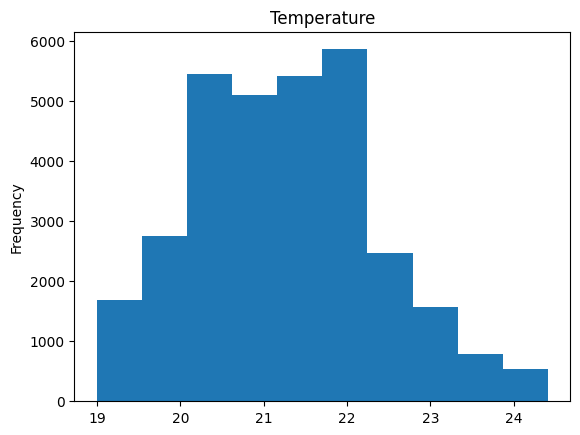

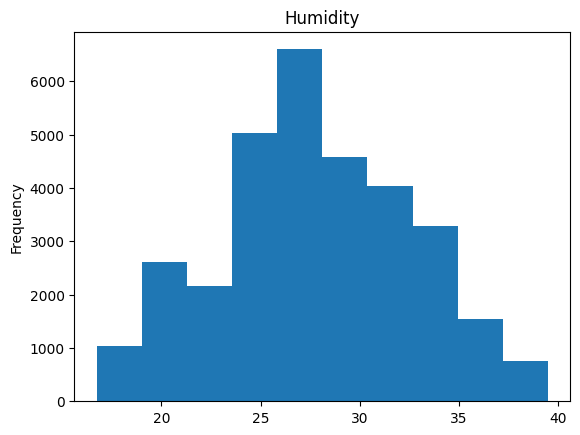

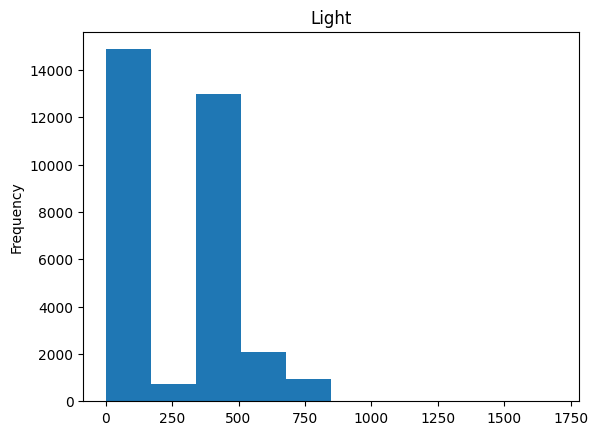

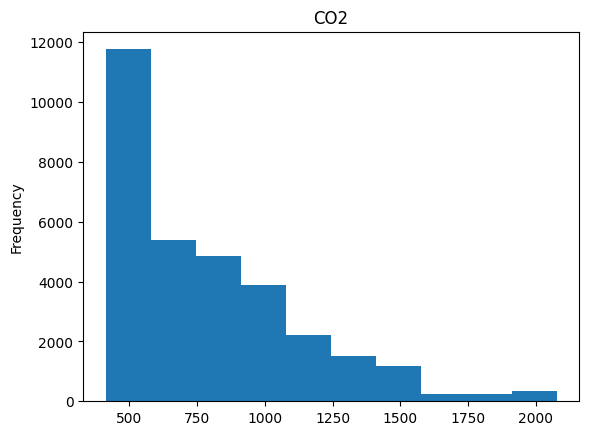

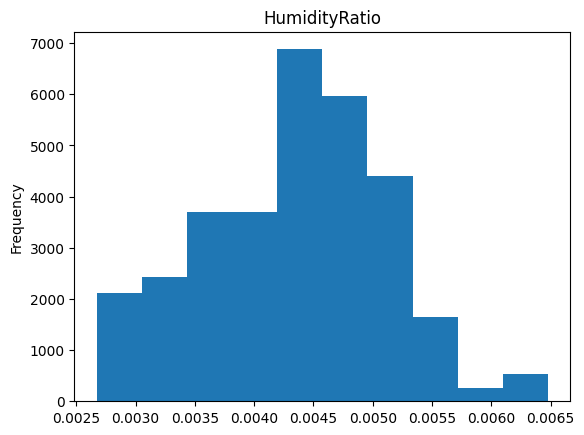

In [8]:
import matplotlib.pyplot as plt

for col in df_balanced.columns[:-1]:
    plt.title(col)
    df_balanced[col].plot.hist() #plotting the histogram with Pandas
    plt.show()

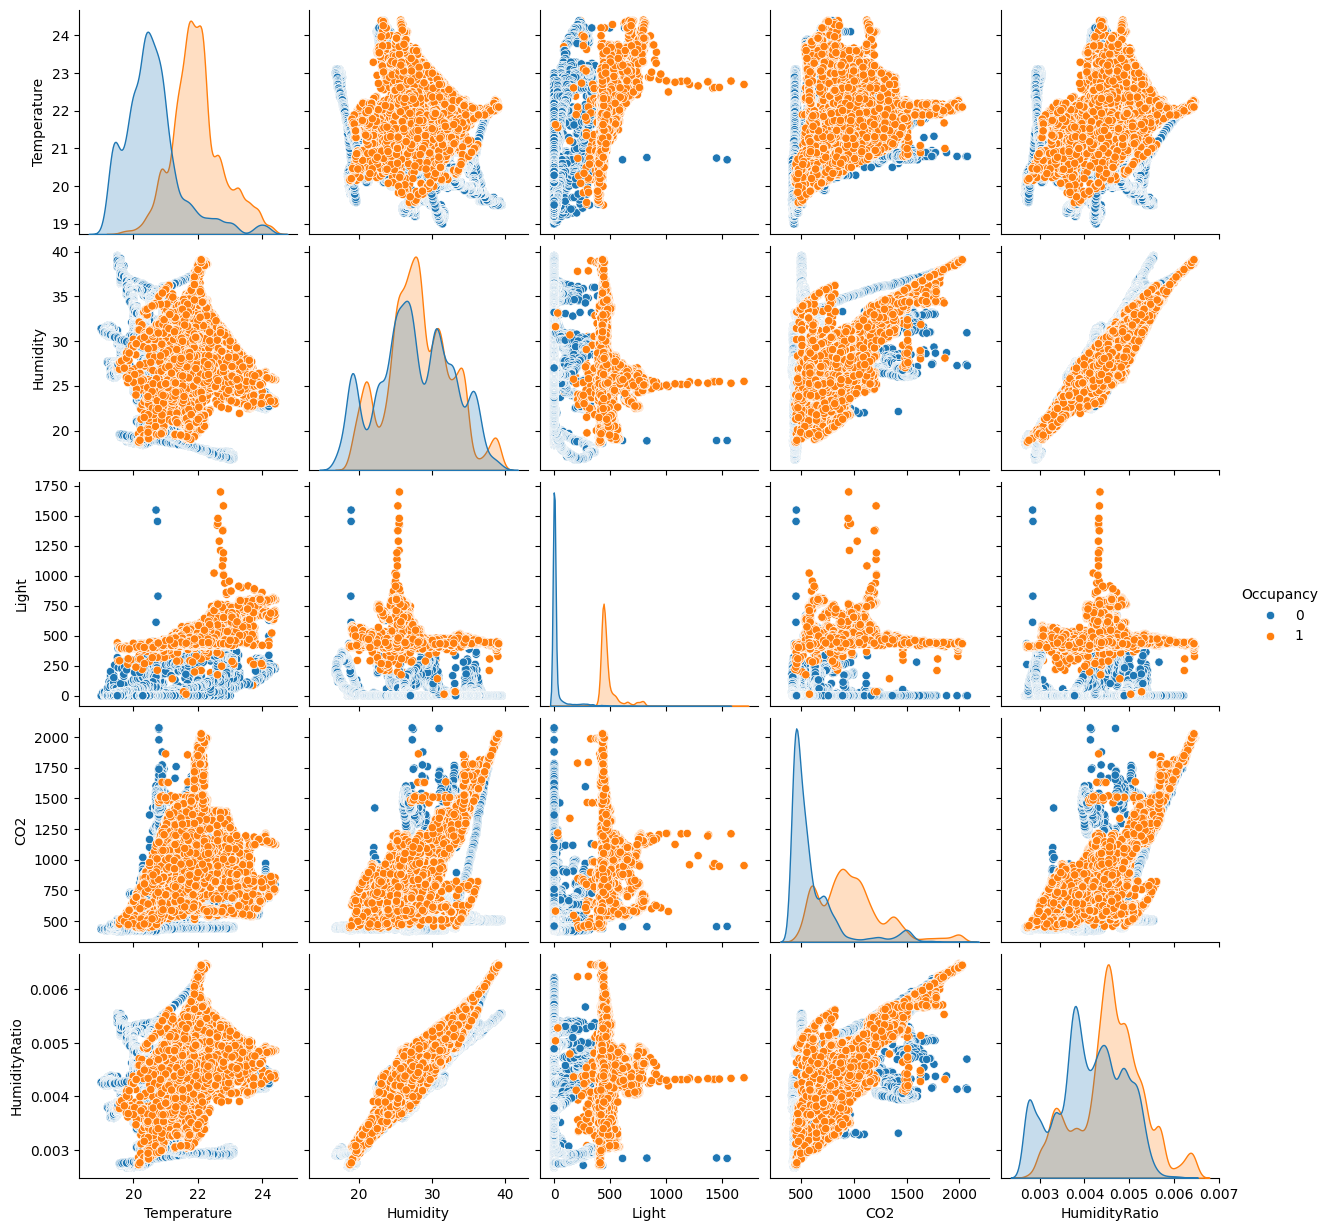

In [9]:
import seaborn as sns
sns.pairplot(df_balanced, hue='Occupancy')

#### Splitting Data into Training and Test Sets

In [10]:
from sklearn.model_selection import train_test_split

# Features and labels
X = df_balanced[["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]]
y = df_balanced['Occupancy']

SEED = 42

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size = 0.20,
                                                    random_state = SEED)

In [11]:
xtrain_samples = X_train.shape[0]
xtest_samples = X_test.shape[0]

print(f'There are {xtrain_samples} samples for training and {xtest_samples} samples for testing.')

There are 25296 samples for training and 6324 samples for testing.


### Training the Model

In [12]:
from sklearn.svm import SVC

svc = SVC(kernel='linear', verbose=True)

svc.fit(X_train, y_train)

[LibSVM]

SVC(kernel='linear', verbose=True)

### Making Predictions

In [13]:
y_pred = svc.predict(X_test)

### Evaluating the Model

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      3162
           1       0.99      1.00      0.99      3162

    accuracy                           0.99      6324
   macro avg       0.99      0.99      0.99      6324
weighted avg       0.99      0.99      0.99      6324



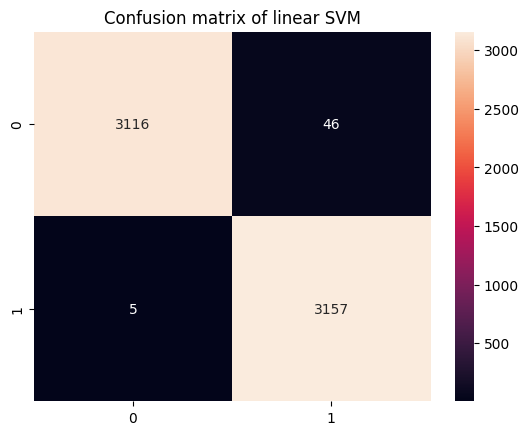

In [14]:
from sklearn.metrics import classification_report, confusion_matrix

cm = confusion_matrix(y_test,y_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('Confusion matrix of linear SVM') # fmt='d' formats the numbers as digits, which means integers

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     12648
           1       0.99      1.00      0.99     12648

    accuracy                           0.99     25296
   macro avg       0.99      0.99      0.99     25296
weighted avg       0.99      0.99      0.99     25296



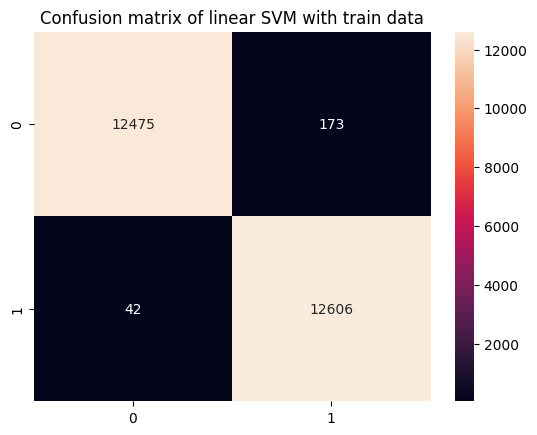

In [15]:
y_pred_train = svc.predict(X_train)

cm_train = confusion_matrix(y_train,y_pred_train)
sns.heatmap(cm_train, annot=True, fmt='d').set_title('Confusion matrix of linear SVM with train data')

print(classification_report(y_train,y_pred_train))

### Hyperparamter Tuning (for model verification only)

In [16]:
svc_c = SVC(kernel='linear', C=0.00001)
svc_c.fit(X_train, y_train)
y_pred_c = svc_c.predict(X_test)

              precision    recall  f1-score   support

           0       1.00      0.98      0.99      3162
           1       0.98      1.00      0.99      3162

    accuracy                           0.99      6324
   macro avg       0.99      0.99      0.99      6324
weighted avg       0.99      0.99      0.99      6324



Text(0.5, 1.0, 'Confusion matrix of linear SVM with C=0.00001')

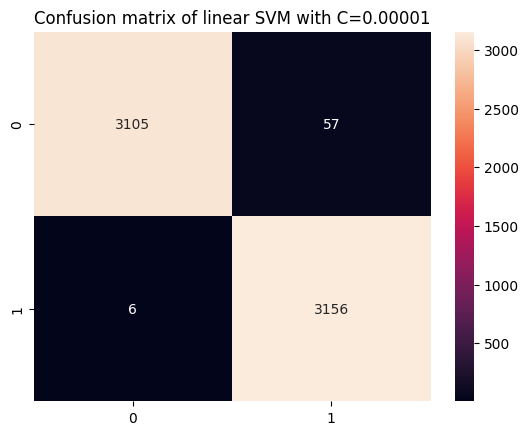

In [17]:
print(classification_report(y_test, y_pred_c))

cm_c = confusion_matrix(y_test, y_pred_c)
sns.heatmap(cm_c, annot=True, fmt='d').set_title('Confusion matrix of linear SVM with C=0.00001')

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     12648
           1       0.98      1.00      0.99     12648

    accuracy                           0.99     25296
   macro avg       0.99      0.99      0.99     25296
weighted avg       0.99      0.99      0.99     25296



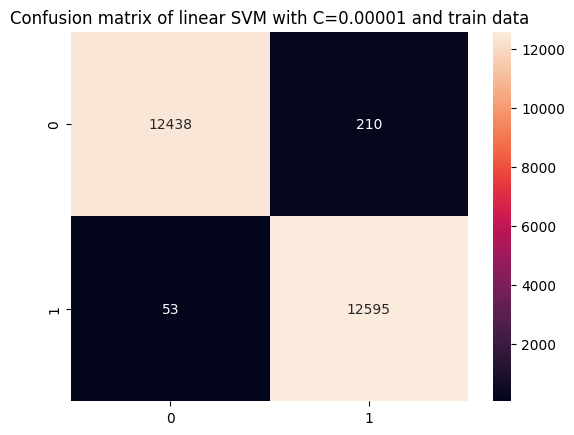

In [18]:
y_pred_ct = svc_c.predict(X_train)

cm_ct = confusion_matrix(y_train, y_pred_ct)
sns.heatmap(cm_ct, annot=True, fmt='d').set_title('Confusion matrix of linear SVM with C=0.00001 and train data')

print(classification_report(y_train, y_pred_ct))

this has lower recall for class 0 and precision for class 1... no improvements shown for other C values.

####